# Exercise 1: Real Estate Unsold Property Analysis Using PCA

**Subject:** Machine Learning Lab  
**Topic:** Principal Component Analysis (PCA)

## Aim
To apply Principal Component Analysis (PCA) to real estate data to reduce dimensionality and visualize patterns among unsold properties.

Real Estate Dataset:


,Area_sqft,Bedrooms,Age_years,Price_lakhs,Unsold
0,800,1,10,25,1
1,950,2,8,32,1
2,1100,2,7,38,0
3,1200,2,6,42,1
4,1350,3,5,48,0
5,1500,3,4,55,0
6,1650,3,3,60,1
7,1800,4,2,68,0
8,900,1,9,28,1
9,1050,2,7,35,0



Explained variance ratio:
[0.97847971 0.01540781]
Total variance retained: 99.39 %

PCA-transformed data:


,Principal Component 1,Principal Component 2,Unsold
0,-3.418172,-0.101847,Unsold
1,-2.050287,0.392390,Unsold
2,-1.445078,0.049258,Not Unsold
3,-0.975849,-0.204124,Unsold
4,0.161953,0.382725,Not Unsold
5,0.799974,0.020863,Not Unsold
6,1.372370,-0.303540,Unsold
7,2.575797,0.245850,Not Unsold
8,-2.981755,-0.336499,Unsold
9,-1.613870,0.157738,Not Unsold


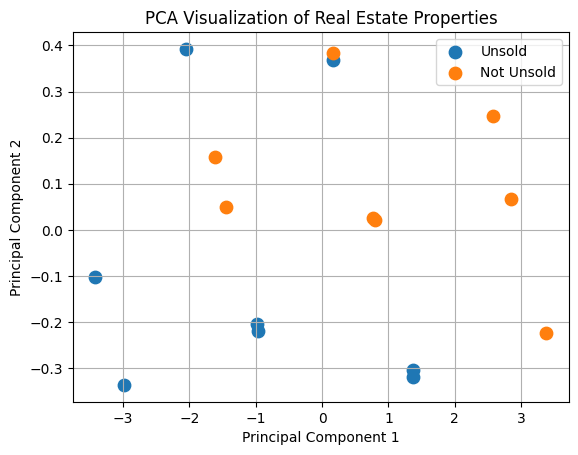

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Illustrative real estate dataset
data = {
    "Area_sqft": [800, 950, 1100, 1200, 1350, 1500, 1650, 1800,
                  900, 1050, 1250, 1400, 1550, 1700, 1900, 2000],
    "Bedrooms": [1, 2, 2, 2, 3, 3, 3, 4,
                 1, 2, 2, 3, 3, 3, 4, 4],
    "Age_years": [10, 8, 7, 6, 5, 4, 3, 2,
                  9, 7, 6, 5, 4, 3, 2, 1],
    "Price_lakhs": [25, 32, 38, 42, 48, 55, 60, 68,
                    28, 35, 40, 46, 52, 58, 72, 78],
    "Unsold": [1, 1, 0, 1, 0, 0, 1, 0,
               1, 0, 1, 1, 0, 1, 0, 0]
}

df = pd.DataFrame(data)

print("Real Estate Dataset:")
display(df)

# Use numerical property features for PCA
features = ["Area_sqft", "Bedrooms", "Age_years", "Price_lakhs"]
X = df[features]

# Standardize before PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    principal_components,
    columns=["Principal Component 1", "Principal Component 2"]
)
pca_df["Unsold"] = df["Unsold"].map({0: "Not Unsold", 1: "Unsold"})

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nPCA-transformed data:")
display(pca_df)

# Visualize properties in two dimensions
for category in pca_df["Unsold"].unique():
    subset = pca_df[pca_df["Unsold"] == category]
    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=category,
        s=80
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Real Estate Properties")
plt.legend()
plt.grid(True)
plt.show()

## Result

Principal Component Analysis (PCA) was successfully applied to the illustrative real estate dataset to reduce four numerical features into two principal components.

- **Total samples:** 16
- **Original features:** 4
- **Principal components:** 2
- **Preprocessing:** StandardScaler
- **Visualization:** Scatter plot of the two principal components, distinguishing unsold and not-unsold properties.

The explained variance ratio was calculated to measure how much information is retained by the two principal components.

## Conclusion

The experiment demonstrated how PCA reduces the dimensionality of real estate data while allowing property observations to be visualized in two dimensions. The scatter plot helps explore patterns between the two property categories. Since the dataset is illustrative and synthetic, the results do not represent actual real estate market conditions.